# Notebook 2 -- OFDM Grid, CP, and Channel Diagonalization

This notebook traces one OFDM frame through cyclic-prefix insertion, a doubly dispersive channel, and DFT-based equalization, with the goal of showing precisely when single-tap equalization is valid and what breaks it.

The effectiveness of CP-OFDM rests on a single algebraic requirement: the effective per-block channel matrix must be **circulant**. When this holds, the DFT diagonalizes the channel and each subcarrier decouples from all others, allowing equalization by a single complex division. The notebook builds the full channel matrices numerically and checks this requirement directly for four synthetic channel cases.

```
                  ┌──────────┐    ┌──────────┐    ┌──────────┐
  QAM symbols --> │   IFFT   │--> │ Insert   │--> │ Doubly   │
   X_tf[n,m]      │ per sym  │    │   CP     │    │Dispersive│
                  └──────────┘    └──────────┘    │ Channel  │
                                                   └─────┬────┘
                  ┌──────────┐    ┌──────────┐          │
  X̂_tf[n,m]  <-- │   FFT    │<-- │ Remove   │<─────────┘
                  │ per sym  │    │   CP     │
                  └──────────┘    └──────────┘
                       │
                       ▼
              single-tap MMSE per subcarrier
```

**The notebook covers:**
- An intentionally small OFDM grid so that full channel matrices fit on screen
- Four synthetic channels from `DDPathCIRGenerator`: static multipath, pure Doppler, sparse doubly dispersive, fractional Doppler
- Explicit construction of the full time-domain channel matrix with and without CP for each channel case
- A circulant-deviation analysis quantifying how much each channel deviates from the structure that CP is supposed to impose
- Per-block DFT transformation and ICI ratio measurement
- Single-tap MMSE equalization with constellation and MSE comparison across all four channel cases

**Key observations covered:**
- For static multipath with CP length at least as large as the maximum delay spread, the block channel matrix is exactly circulant; the DFT diagonalizes it and single-tap equalization reduces MSE to the noise floor
- Doppler causes the channel to vary within one OFDM symbol period, breaking the circulant structure and producing off-diagonal terms in the frequency-domain channel matrix
- These off-diagonal terms are intercarrier interference (ICI); the ICI ratio is substantial for the pure Doppler case and measurable for the doubly dispersive cases
- The MSE after single-tap equalization is bounded below by the ICI, not by the noise -- increasing SNR does not improve performance once ICI dominates

---

**Table of Contents**

- [1. Imports and Parameters](#1-imports-and-parameters)
- [2. Define Synthetic Channel Cases](#2-define-synthetic-channel-cases)
- [3. OFDM Time-Frequency Grid](#3-ofdm-time-frequency-grid)
- [4. OFDM Modulation and Cyclic Prefix Insertion](#4-ofdm-modulation-and-cyclic-prefix-insertion)
- [5. Channel Magnitude and Phase](#5-channel-magnitude-and-phase)
- [6. Full Effective Time-Domain Channel Matrix without CP](#6-full-effective-time-domain-channel-matrix-without-cp)
- [7. Full Effective Time-Domain Channel Matrix with CP](#7-full-effective-time-domain-channel-matrix-with-cp)
- [8. One Block without CP](#8-one-block-without-cp)
- [9. One Block with CP](#9-one-block-with-cp)
- [10. Circulant Structure and CP](#10-circulant-structure-and-cp)
- [11. DFT Effect and Intercarrier Interference](#11-dft-effect-and-intercarrier-interference)
- [12. Pass One OFDM Frame through Each Channel](#12-pass-one-ofdm-frame-through-each-channel)
- [13. Single-Tap Equalization and Constellation Comparison](#13-single-tap-equalization-and-constellation-comparison)
- [14. Interpretation](#14-interpretation)

## 1. Imports and Parameters

The grid dimensions are intentionally small so that the full effective channel matrices can be visualized directly. A larger grid would make the matrix structure harder to inspect but would not change the conclusions.

`CP_LEN` is set to match the maximum delay tap across the channel cases defined below. This is the minimum CP length that guarantees the block channel matrix is circulant for static multipath -- a CP shorter than the maximum delay spread would leave inter-block interference that the circular-convolution argument cannot absorb.

In [1]:
# Make local src/ imports work regardless of notebook location.
# Small dimensions keep the effective channel matrices easy to visualize.
from pathlib import Path
import sys

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.ticker import MaxNLocator

# Find repository root
path = Path.cwd()
while path != path.parent and not (path / "src").exists():
    path = path.parent

ROOT = path
sys.path.append(str(ROOT / "src"))

from otfs_sim.phy.channel.generate_channel_cir import DDPathCIRGenerator
from otfs_sim.phy.channel.channel_utils import cir_to_h_time

np.random.seed(7)
tf.random.set_seed(7)

N = 8                         # number of OFDM symbols / time slots
M = 16                         # number of subcarriers
CP_LEN = 4                     # cyclic prefix length
SUBCARRIER_SPACING = 15e3
BANDWIDTH = M * SUBCARRIER_SPACING

NUM_TIME_SAMPLES_NO_CP = N * M
NUM_TIME_SAMPLES_WITH_CP = N * (M + CP_LEN)

L_MIN = 0
L_MAX = CP_LEN

QPSK = np.array(
    [1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j],
    dtype=np.complex128,
) / np.sqrt(2)

print("ROOT:", ROOT)
print("OFDM grid: N =", N, "M =", M)
print("Samples without CP:", NUM_TIME_SAMPLES_NO_CP)
print("Samples with CP:", NUM_TIME_SAMPLES_WITH_CP)
print("Bandwidth:", BANDWIDTH)
print("Delay resolution [ns]:", 1e9 / BANDWIDTH)



ROOT: d:\Aya Documents\Education\Uni Bremen\Thesis\Code\Thesis-Clean\otfs-sim
OFDM grid: N = 8 M = 16
Samples without CP: 128
Samples with CP: 160
Bandwidth: 240000.0
Delay resolution [ns]: 4166.666666666667


## 2. Define Synthetic Channel Cases

The four channel cases are the same controlled examples used in Notebook 1, now applied to an OFDM frame so that the matrix-level consequences of each propagation effect become visible.

| Case | Delay | Doppler | Effect on block matrix |
|---|---|---|---|
| Static multipath | $\ell_i \neq 0$ | $\kappa_i = 0$ | Circulant (with sufficient CP) |
| Pure Doppler | $\ell_i = 0$ | $\kappa_i \neq 0$ | Time-varying; circulant structure broken |
| Sparse doubly dispersive | $\ell_i \neq 0$ | $\kappa_i \in \mathbb{Z} \setminus \{0\}$ | Circulant structure partially broken |
| Fractional Doppler | $\ell_i \neq 0$ | $\kappa_i \notin \mathbb{Z}$ | Circulant structure broken; sinc leakage |

Each channel is generated using `DDPathCIRGenerator` and converted to the discrete time-domain representation `h_time` via `cir_to_h_time`.

In [2]:
# Convert each synthetic DD channel into a Sionna CIR and h_time representation.
synthetic_channels = {
    "Static multipath": {
        "g_i": [1.0 + 0.0j, 0.65 + 0.25j, 0.35 - 0.20j],
        "l_i": [0, 3, 6],
        "k_i": [0.0, 0.0, 0.0],
    },
    "Pure Doppler": {
        "g_i": [1.0 + 0.0j, 0.7 - 0.15j],
        "l_i": [0, 0],
        "k_i": [0.0, 3.0],
    },
    "Sparse doubly dispersive": {
        "g_i": [1.0 + 0.0j, 0.75 + 0.25j, 0.5 - 0.35j, 0.35 + 0.1j],
        "l_i": [0, 2, 5, 7],
        "k_i": [0.0, 1.5, -2.0, 4.0],
    },
    "Fractional Doppler": {
        "g_i": [1.0 + 0.0j, 0.7 + 0.2j, 0.45 - 0.25j],
        "l_i": [0, 3, 6],
        "k_i": [0.0, 2.7, -1.4],
    },
}

channel_data = {}

for name, params in synthetic_channels.items():
    generator = DDPathCIRGenerator(
        g_i=params["g_i"],
        l_i=params["l_i"],
        k_i=params["k_i"],
    )

    a, tau = generator(
        batch_size=1,
        num_time_steps=NUM_TIME_SAMPLES_WITH_CP,
        bandwidth=BANDWIDTH,
    )

    h_time, l_min_used, l_max_used = cir_to_h_time(
        a=a,
        tau=tau,
        bandwidth=BANDWIDTH,
        l_min=L_MIN,
        l_max=L_MAX,
        normalize=False,
    )

    channel_data[name] = {
        "g_i": np.array(params["g_i"], dtype=np.complex128),
        "l_i": np.array(params["l_i"], dtype=int),
        "k_i": np.array(params["k_i"], dtype=float),
        "a": a,
        "tau": tau,
        "h_time": h_time,
        "l_min_used": l_min_used,
        "l_max_used": l_max_used,
    }

    print("=" * 80)
    print(name)
    print("g_i:", params["g_i"])
    print("l_i:", params["l_i"])
    print("k_i:", params["k_i"])
    print("a shape:", a.shape)
    print("tau shape:", tau.shape)
    print("h_time shape:", h_time.shape)


Static multipath
g_i: [(1+0j), (0.65+0.25j), (0.35-0.2j)]
l_i: [0, 3, 6]
k_i: [0.0, 0.0, 0.0]
a shape: (1, 1, 1, 1, 1, 3, 160)
tau shape: (1, 1, 1, 3)
h_time shape: (1, 1, 1, 1, 1, 160, 5)
Pure Doppler
g_i: [(1+0j), (0.7-0.15j)]
l_i: [0, 0]
k_i: [0.0, 3.0]
a shape: (1, 1, 1, 1, 1, 2, 160)
tau shape: (1, 1, 1, 2)
h_time shape: (1, 1, 1, 1, 1, 160, 5)
Sparse doubly dispersive
g_i: [(1+0j), (0.75+0.25j), (0.5-0.35j), (0.35+0.1j)]
l_i: [0, 2, 5, 7]
k_i: [0.0, 1.5, -2.0, 4.0]
a shape: (1, 1, 1, 1, 1, 4, 160)
tau shape: (1, 1, 1, 4)
h_time shape: (1, 1, 1, 1, 1, 160, 5)
Fractional Doppler
g_i: [(1+0j), (0.7+0.2j), (0.45-0.25j)]
l_i: [0, 3, 6]
k_i: [0.0, 2.7, -1.4]
a shape: (1, 1, 1, 1, 1, 3, 160)
tau shape: (1, 1, 1, 3)
h_time shape: (1, 1, 1, 1, 1, 160, 5)


## 3. OFDM Time-Frequency Grid

The $N \times M$ array $X_\text{tf}[n, m]$ holds one QAM symbol at each (OFDM symbol, subcarrier) position. This is the natural representation for OFDM: each position is an independent resource unit that, under ideal conditions, experiences a flat complex gain.

The phase plot shows the QPSK alphabet: four distinct phases distributed across the grid.

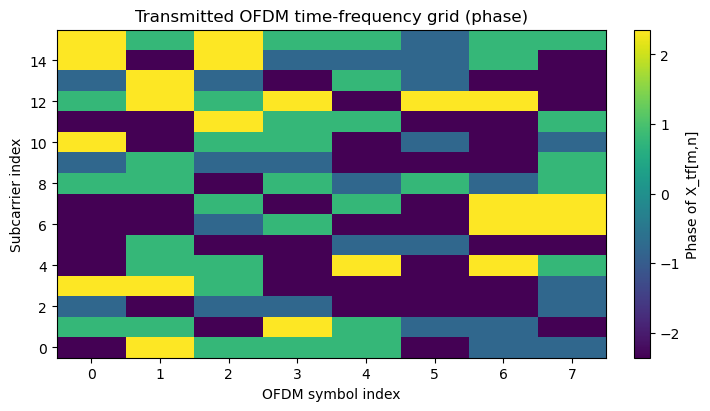

In [3]:
# X_tf follows the OFDM convention [symbol, subcarrier].
symbol_indices = np.random.randint(0, len(QPSK), size=(N, M))
X_tf = QPSK[symbol_indices]  # [OFDM symbol, subcarrier]

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
im = ax.imshow(np.angle(X_tf).T, aspect="auto", origin="lower", cmap="viridis")
ax.set_title("Transmitted OFDM time-frequency grid (phase)")
ax.set_xlabel("OFDM symbol index")
ax.set_ylabel("Subcarrier index")
fig.colorbar(im, ax=ax, label="Phase of X_tf[m,n]")
plt.show()


## 4. OFDM Modulation and Cyclic Prefix Insertion

Standard CP-OFDM modulation proceeds in two steps.

**Step 1 -- IFFT per symbol.** Each row of $X_\text{tf}$ is transformed to the time domain by an $M$-point IFFT, producing one OFDM symbol vector $\tilde{x}_n \in \mathbb{C}^M$. The IFFT spreads each QAM symbol across all $M$ time-domain samples so that every time sample carries contributions from all subcarriers.

**Step 2 -- Cyclic prefix.** The last `CP_LEN` samples of each OFDM symbol are prepended to it. The CP serves two purposes:

- It absorbs the inter-block interference caused by channel delay spread, provided that the CP length is at least as large as the maximum channel delay.
- It converts the linear convolution introduced by the channel into a circular convolution within each block, which is the algebraic prerequisite for DFT diagonalization.

The heatmap shows all $N$ blocks after CP insertion. The dashed white line marks the CP boundary; the region to its left within each block is the CP.

X_tf shape: (8, 16)
x_blocks_no_cp shape: (8, 16)
x_blocks_with_cp shape: (8, 20)
x_time_no_cp shape: (128,)
x_time_with_cp shape: (160,)


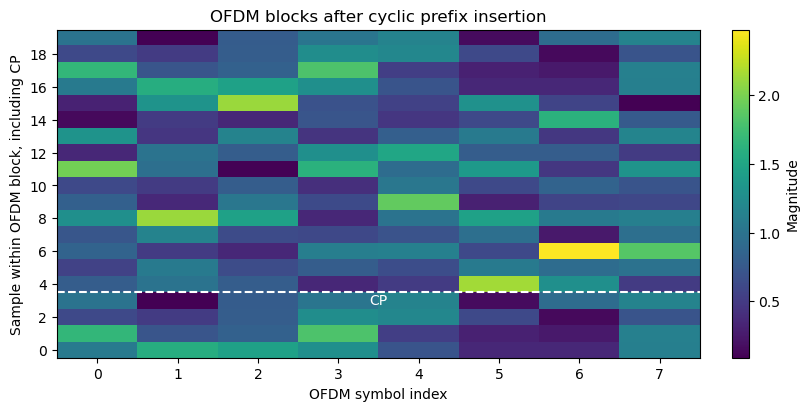

In [14]:
# Apply an M-point IFFT independently to every OFDM symbol.
# Build the cyclic prefix from the last CP_LEN useful samples.
# Serialize the OFDM frame into a continuous time-domain waveform.
x_blocks_no_cp = np.fft.ifft(X_tf, n=M, axis=1) * np.sqrt(M)  # [N, M]
cp = x_blocks_no_cp[:, -CP_LEN:]
x_blocks_with_cp = np.concatenate([cp, x_blocks_no_cp], axis=1)  # [N, CP_LEN + M]

x_time_no_cp = x_blocks_no_cp.reshape(-1)
x_time_with_cp = x_blocks_with_cp.reshape(-1)

print("X_tf shape:", X_tf.shape)
print("x_blocks_no_cp shape:", x_blocks_no_cp.shape)
print("x_blocks_with_cp shape:", x_blocks_with_cp.shape)
print("x_time_no_cp shape:", x_time_no_cp.shape)
print("x_time_with_cp shape:", x_time_with_cp.shape)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
im = ax.imshow(np.abs(x_blocks_with_cp).T, aspect="auto", origin="lower", cmap="viridis")
ax.axhline(CP_LEN - 0.5, color="white", linestyle="--", linewidth=1.5)
ax.set_title("OFDM blocks after cyclic prefix insertion")
ax.set_ylabel("Sample within OFDM block, including CP")
ax.set_xlabel("OFDM symbol index")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.text(X_tf.shape[0] / 2 - 0.5, CP_LEN - 1.0, "CP", color="white", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Magnitude")
plt.show()

## 5. Channel Magnitude and Phase

The discrete time-varying impulse response `h_time[q, l]` is visualized for all four channel cases.

**Magnitude:** active delay taps appear as bright horizontal lines. Their positions on the delay axis reflect the physical path delays in units of the sampling interval. For static and Doppler channels alike the magnitude is constant over time -- Doppler modulates the phase of each tap, not its magnitude.

**Phase:** for a static channel the phase at each active tap is constant. For Doppler channels the phase ramps linearly across time at a rate proportional to the Doppler tap $\kappa_i$. This time-varying phase is precisely what breaks the circulant structure of the block channel matrix, as shown in Sections 10 and 11.

Phase is masked where the channel magnitude is effectively zero.

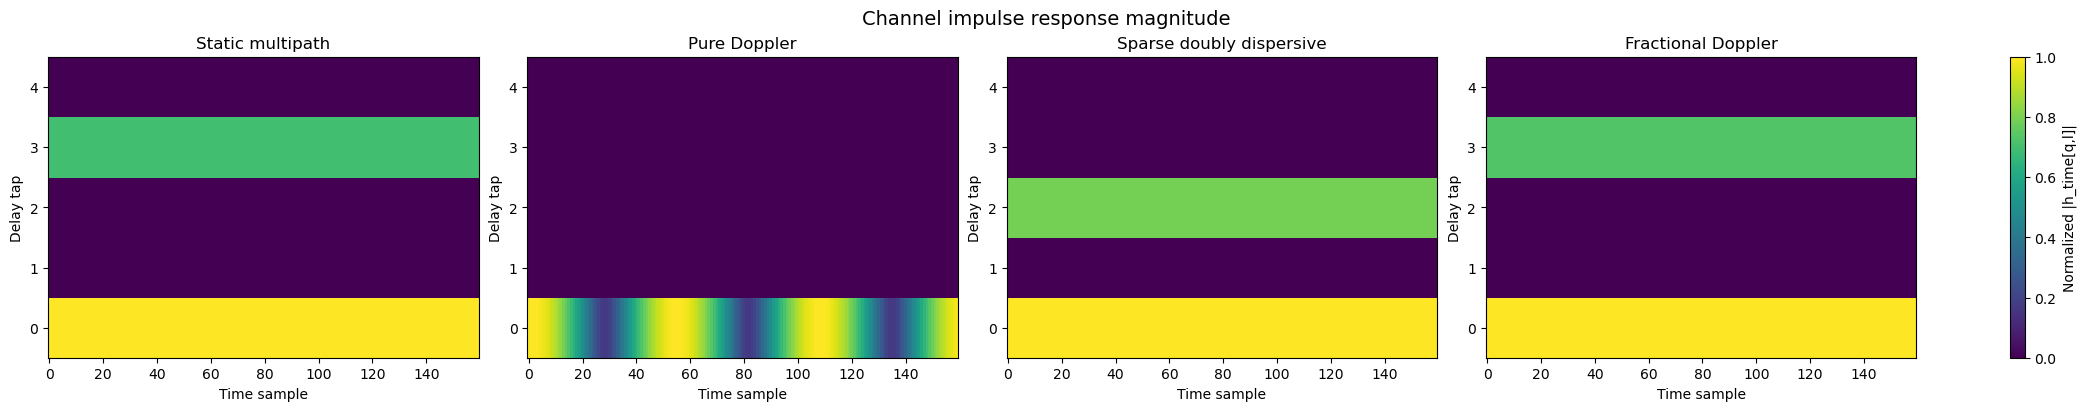

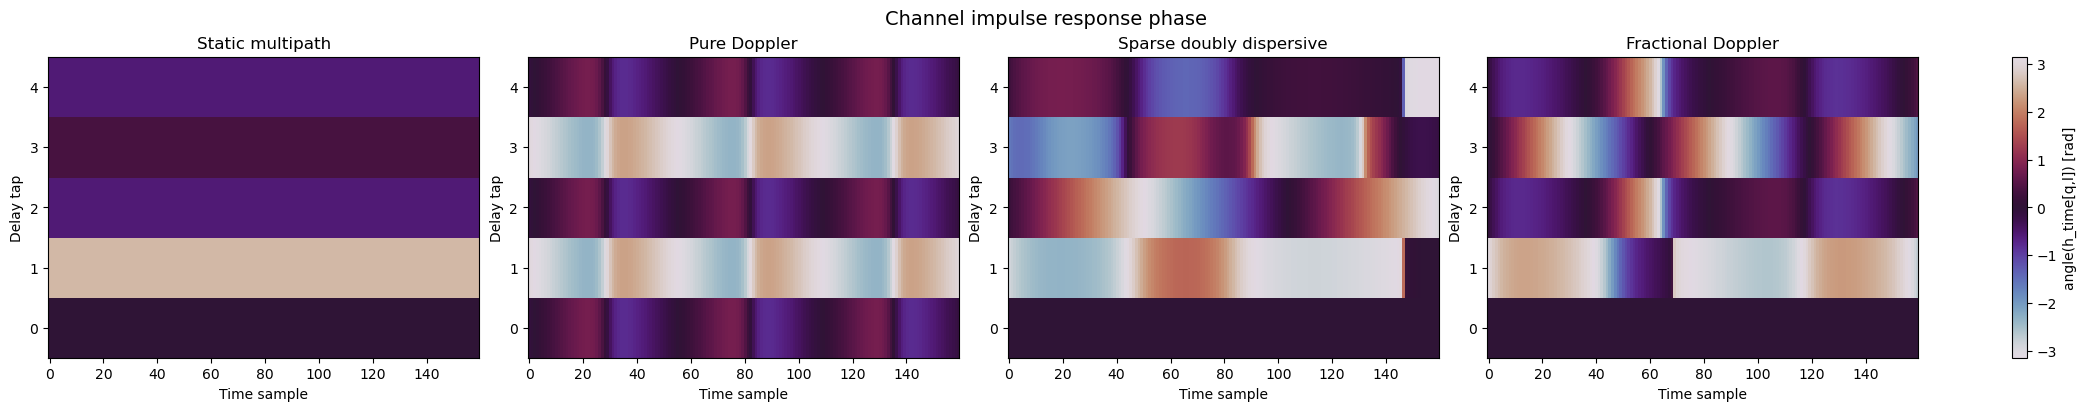

In [5]:
# h_time is indexed as [time, delay].
# Plot as [delay, time] to match the usual channel visualization convention.
# Hide phase where the channel tap magnitude is effectively zero.
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]  # [time, delay]
    h_abs = np.abs(h).T
    h_abs = h_abs / (np.max(h_abs) + 1e-12)

    im = ax.imshow(h_abs, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |h_time[q,l]|")
fig.suptitle("Channel impulse response magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]
    h_phase = np.angle(h).T
    h_abs = np.abs(h).T
    h_phase = np.ma.array(h_phase, mask=(h_abs < 1e-10))

    im = ax.imshow(h_phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(h_time[q,l]) [rad]")
fig.suptitle("Channel impulse response phase", fontsize=14)
plt.show()


## 6. Full Effective Time-Domain Channel Matrix without CP

The matrix $G_\text{no-CP}$ maps the serialized useful time-domain samples (without CP) to the received samples via the channel's linear convolution. Entry $G[q,\, q-\ell] = h[q, \ell]$ records the contribution of the transmitted sample at time $q - \ell$ to the received sample at time $q$ through delay tap $\ell$.

This produces a lower banded matrix: each row has at most $L_\text{max} + 1$ non-zero entries, aligned along sub-diagonals offset by $0$ through $L_\text{max}$.

The non-zero positions are the same for all four channel cases -- Doppler affects the *values* of those entries (visible in the phase plot) but not their *positions*. The faint white grid lines mark boundaries between OFDM blocks. The inter-block interference caused by delay spread appears as non-zero entries below the block diagonal: a sample transmitted near the end of one block bleeds into the next through the channel's delay spread.

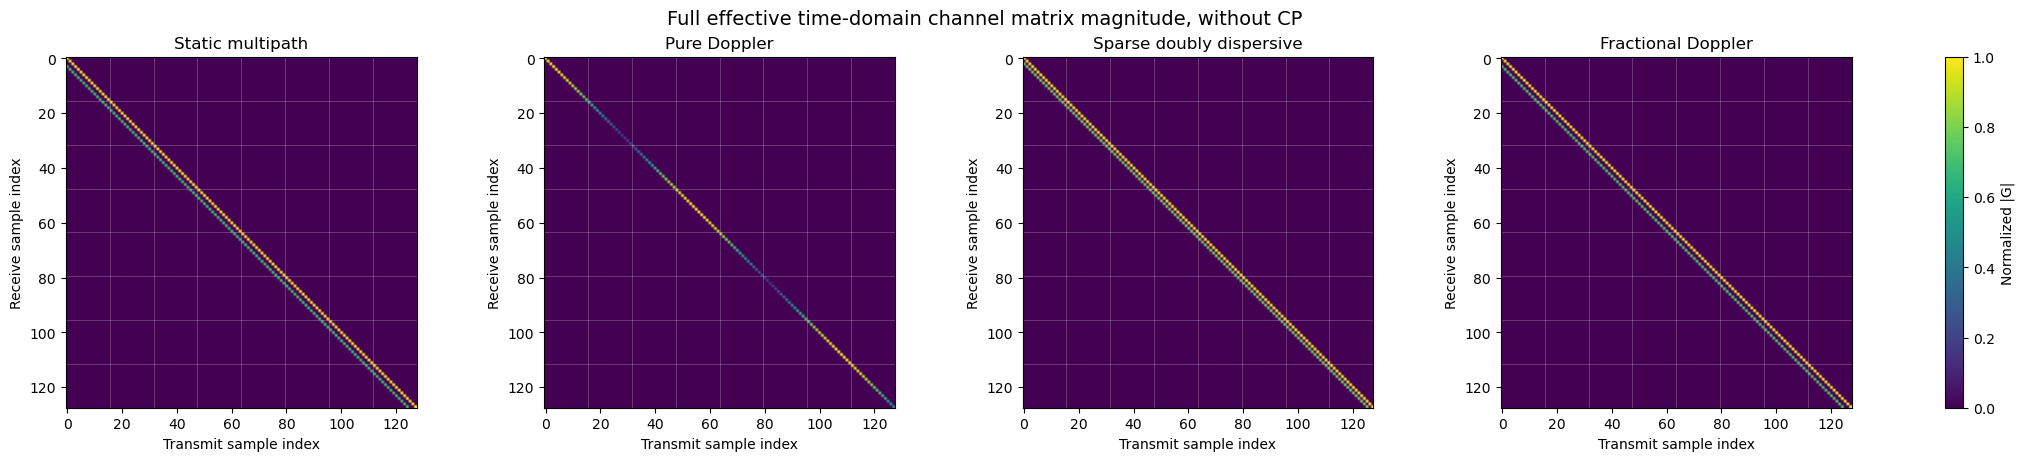

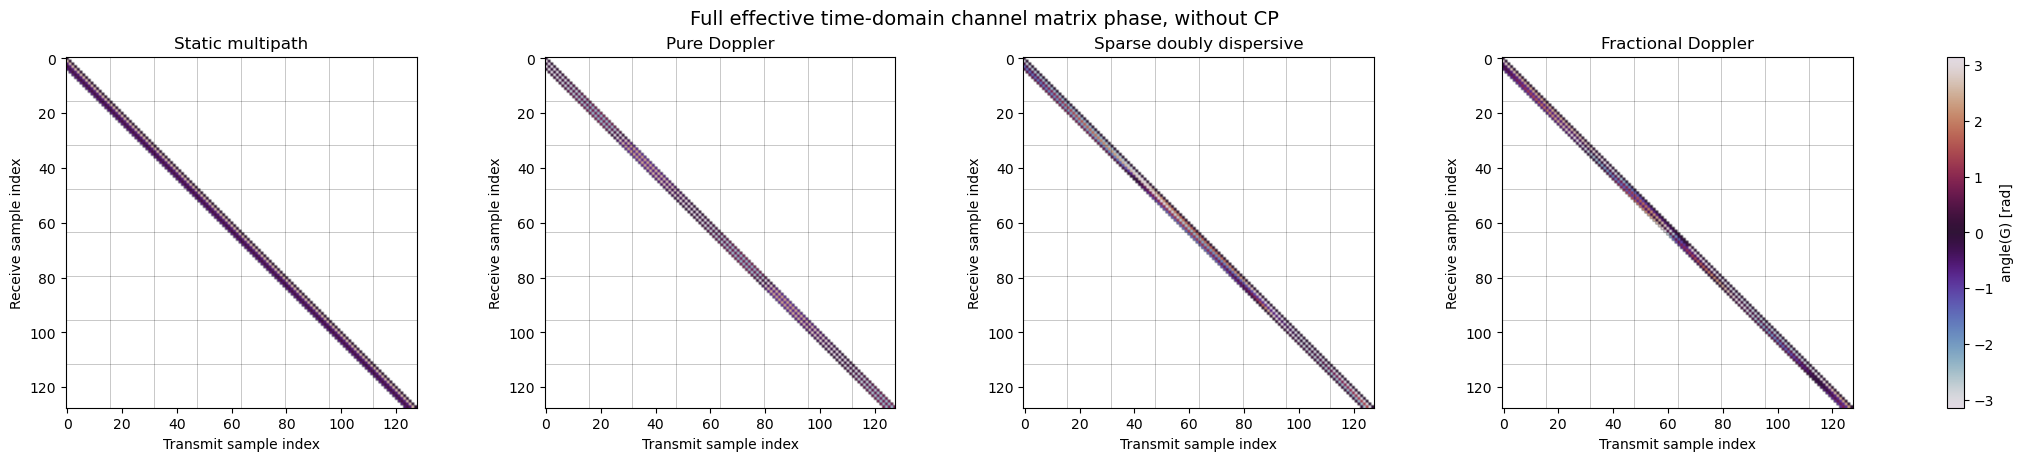

In [6]:
# Build the full linear-convolution matrix G such that y = Gx.
# Place tap ell on the ell-th lower diagonal of the channel matrix.
for name, data in channel_data.items():
    h_full = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]  # [time, delay]

    G_full_no_cp = np.zeros(
        (NUM_TIME_SAMPLES_NO_CP, NUM_TIME_SAMPLES_NO_CP),
        dtype=np.complex128,
    )

    for q in range(NUM_TIME_SAMPLES_NO_CP):
        for ell in range(h_full.shape[1]):
            if q - ell >= 0 and q < h_full.shape[0]:
                G_full_no_cp[q, q - ell] = h_full[q, ell]

    data["G_full_no_cp"] = G_full_no_cp

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G_abs = np.abs(data["G_full_no_cp"])
    G_abs = G_abs / (np.max(G_abs) + 1e-12)

    im = ax.imshow(G_abs, aspect="equal", origin="upper", cmap="viridis", vmin=0, vmax=1)
    for b in range(1, N):
        pos = b * M

        ax.axvline(
            pos - 0.5,
            color="white",
            linewidth=0.5,
            alpha=0.3,
        )

        ax.axhline(
            pos - 0.5,
            color="white",
            linewidth=0.5,
            alpha=0.3,
        )
    ax.set_title(name)
    ax.set_xlabel("Transmit sample index")
    ax.set_ylabel("Receive sample index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |G|")
fig.suptitle("Full effective time-domain channel matrix magnitude, without CP", fontsize=14)

plt.show()


fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G = data["G_full_no_cp"]
    G_phase = np.angle(G)
    G_phase = np.ma.array(G_phase, mask=(np.abs(G) < 1e-10))

    im = ax.imshow(G_phase, aspect="equal", origin="upper", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    for b in range(1, N):
        pos = b * M

        ax.axvline(
            pos - 0.5,
            color="black",
            linewidth=0.5,
            alpha=0.3,
        )

        ax.axhline(
            pos - 0.5,
            color="black",
            linewidth=0.5,
            alpha=0.3,
        )
    ax.set_title(name)
    ax.set_xlabel("Transmit sample index")
    ax.set_ylabel("Receive sample index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(G) [rad]")
fig.suptitle("Full effective time-domain channel matrix phase, without CP", fontsize=14)
plt.show()


## 7. Full Effective Time-Domain Channel Matrix with CP

After CP insertion, propagation, and CP removal, the linear convolution is transformed into a per-block circular convolution. The resulting matrix $G_\text{CP}$ maps the useful (CP-free) transmitted samples to the useful received samples.

The key structural difference from $G_\text{no-CP}$ is the wrap-around: delayed samples that would have arrived from outside the block are replaced by the corresponding CP samples, which are copies of the end of the same block. This makes the channel appear circular to the receiver.

For the static multipath case the matrix is block-diagonal with no inter-block interference. For Doppler cases the matrix is still block-diagonal in terms of support, but the values within each block are not those of a simple circulant -- the Doppler-induced phase modulation causes entries along the same sub-diagonal to differ from row to row.

The Doppler effect is visible only in the phase plots; magnitude plots look similar across all four cases.

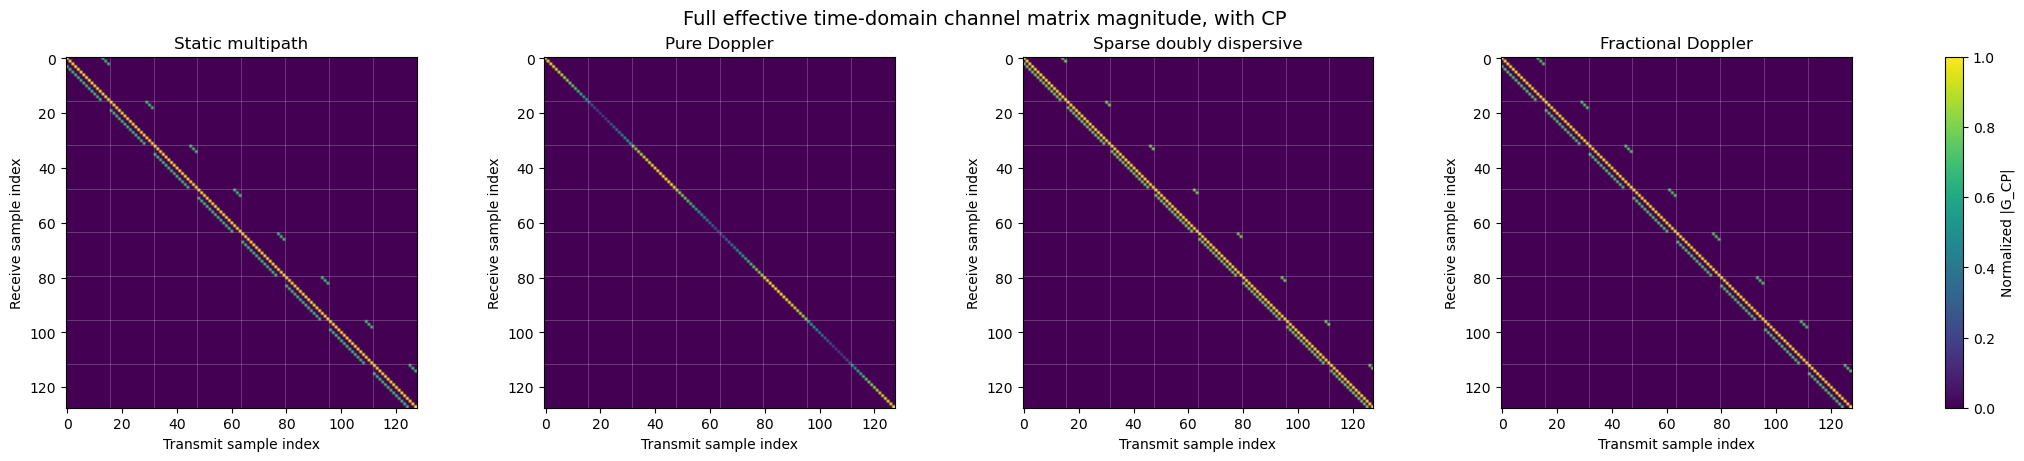

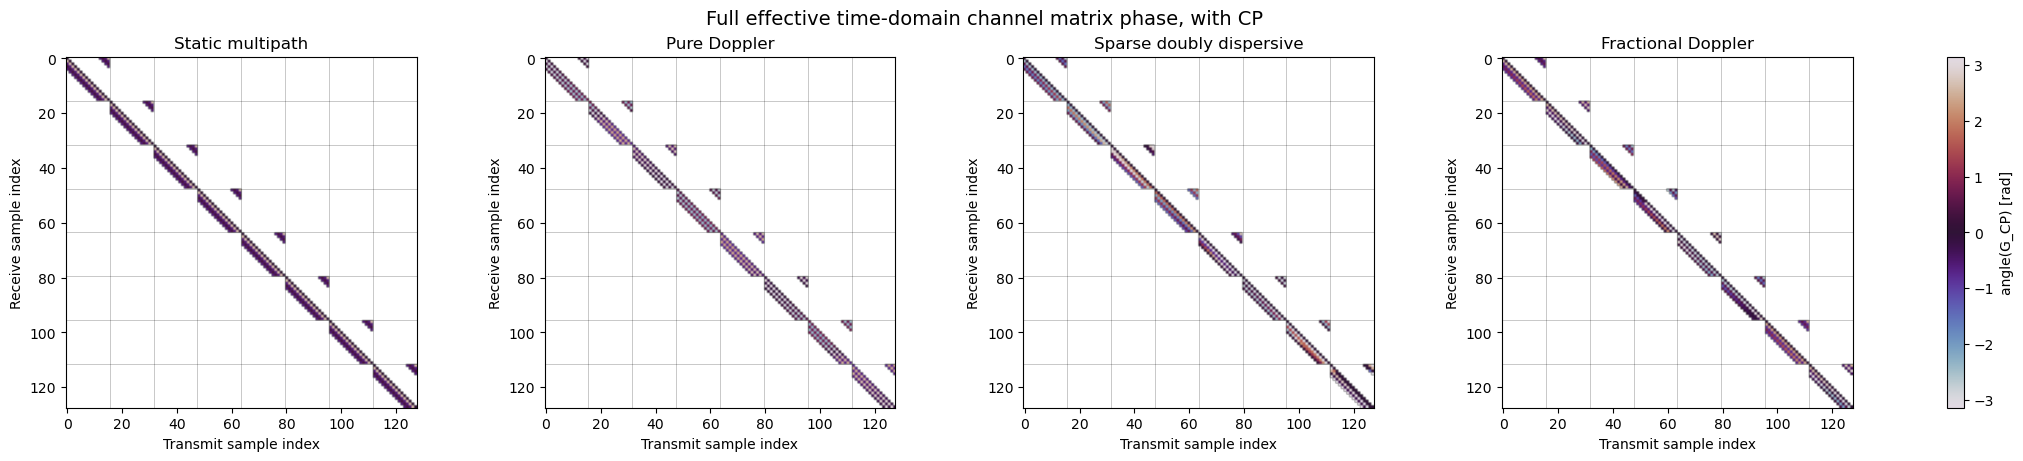

In [7]:
# Build the full CP-aware channel matrix after CP insertion and removal.
# Convert CP-region samples into their wrapped useful-symbol locations.
# Accumulate all channel taps contributing to each transmit/receive pair.
for name, data in channel_data.items():
    h_full = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]  # [time, delay]

    G_full_with_cp = np.zeros(
        (NUM_TIME_SAMPLES_NO_CP, NUM_TIME_SAMPLES_NO_CP),
        dtype=np.complex128,
    )

    for n in range(N):
        block_start_with_cp = n * (M + CP_LEN)
        useful_start_with_cp = block_start_with_cp + CP_LEN

        for m_rx in range(M):
            q = useful_start_with_cp + m_rx
            rx_index = n * M + m_rx

            for ell in range(h_full.shape[1]):
                p = q - ell
                local_p = p - block_start_with_cp

                if 0 <= local_p < (M + CP_LEN) and q < h_full.shape[0]:
                    if local_p < CP_LEN:
                        m_tx = M - CP_LEN + local_p
                    else:
                        m_tx = local_p - CP_LEN

                    tx_index = n * M + m_tx
                    G_full_with_cp[rx_index, tx_index] += h_full[q, ell]

    data["G_full_with_cp"] = G_full_with_cp

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G_abs = np.abs(data["G_full_with_cp"])
    G_abs = G_abs / (np.max(G_abs) + 1e-12)

    im = ax.imshow(G_abs, aspect="equal", origin="upper", cmap="viridis", vmin=0, vmax=1)
    for b in range(1, N):
        pos = b * M

        ax.axvline(
            pos - 0.5,
            color="white",
            linewidth=0.5,
            alpha=0.3,
        )

        ax.axhline(
            pos - 0.5,
            color="white",
            linewidth=0.5,
            alpha=0.3,
        )
    ax.set_title(name)
    ax.set_xlabel("Transmit sample index")
    ax.set_ylabel("Receive sample index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |G_CP|")
fig.suptitle("Full effective time-domain channel matrix magnitude, with CP", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G = data["G_full_with_cp"]
    G_phase = np.angle(G)
    G_phase = np.ma.array(G_phase, mask=(np.abs(G) < 1e-10))

    im = ax.imshow(G_phase, aspect="equal", origin="upper", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    for b in range(1, N):
        pos = b * M

        ax.axvline(
            pos - 0.5,
            color="black",
            linewidth=0.5,
            alpha=0.3,
        )

        ax.axhline(
            pos - 0.5,
            color="black",
            linewidth=0.5,
            alpha=0.3,
        )
    ax.set_title(name)
    ax.set_xlabel("Transmit sample index")
    ax.set_ylabel("Receive sample index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(G_CP) [rad]")
fig.suptitle("Full effective time-domain channel matrix phase, with CP", fontsize=14)
plt.show()


## 8. One Block without CP

Zooming into one representative OFDM block of $G_\text{no-CP}$ shows the per-block channel structure when the CP effect is removed.

Without CP the block matrix is lower triangular and banded: entry $[m_\text{rx}, m_\text{tx}]$ is non-zero only when $0 \leq m_\text{rx} - m_\text{tx} \leq L_\text{max}$. This is a direct linear convolution. The first few received samples in the block cannot accumulate all delayed copies of the transmitted signal because the required earlier samples belong to the preceding block and are not included.

This triangular structure is why the CP is necessary: without it the block channel matrix cannot be made circulant and DFT diagonalization fails even for static channels.

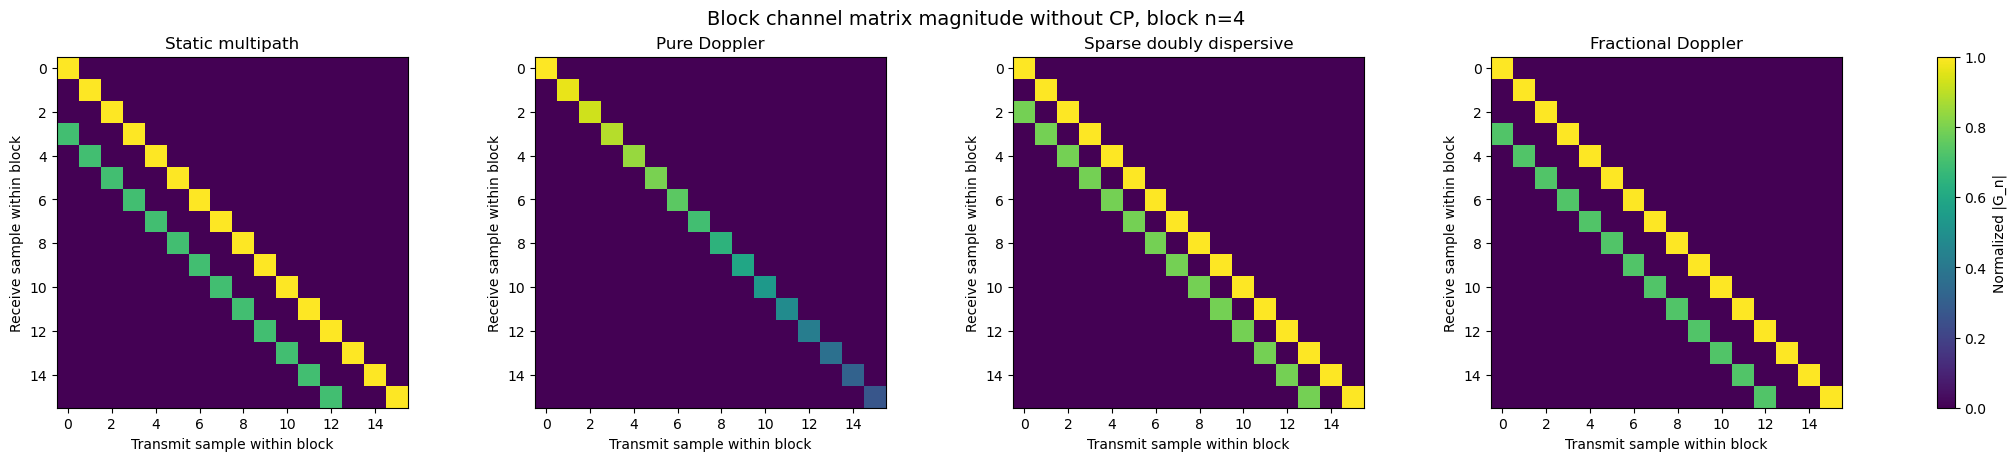

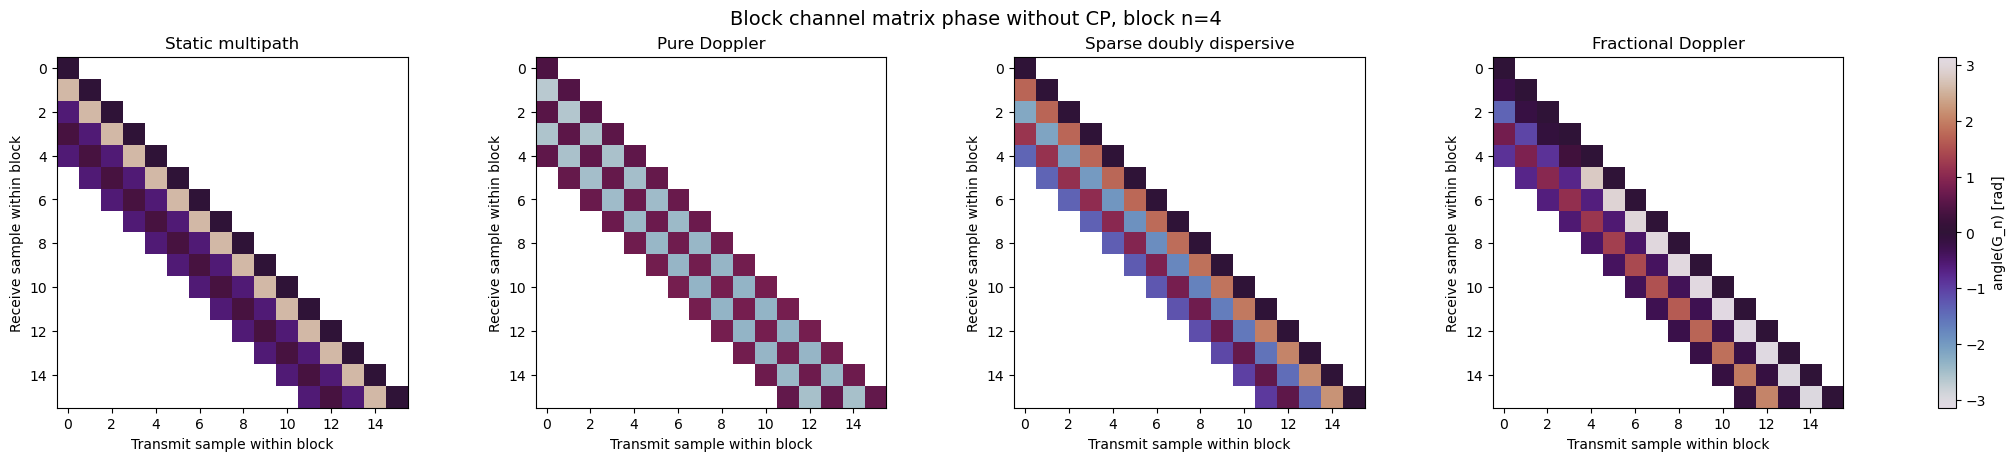

In [8]:
# Extract one representative OFDM block from the full frame matrix.
block_to_show = N // 2

for name, data in channel_data.items():
    start = block_to_show * M
    stop = (block_to_show + 1) * M
    data["G_block_no_cp"] = data["G_full_no_cp"][start:stop, start:stop]

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G_block = data["G_block_no_cp"]
    G_abs = np.abs(G_block)
    G_abs = G_abs / (np.max(G_abs) + 1e-12)

    im = ax.imshow(G_abs, aspect="equal", origin="upper", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("Transmit sample within block")
    ax.set_ylabel("Receive sample within block")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |G_n|")
fig.suptitle(f"Block channel matrix magnitude without CP, block n={block_to_show}", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G_block = data["G_block_no_cp"]
    G_phase = np.angle(G_block)
    G_phase = np.ma.array(G_phase, mask=(np.abs(G_block) < 1e-10))

    im = ax.imshow(G_phase, aspect="equal", origin="upper", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("Transmit sample within block")
    ax.set_ylabel("Receive sample within block")

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(G_n) [rad]")
fig.suptitle(f"Block channel matrix phase without CP, block n={block_to_show}", fontsize=14)
plt.show()


## 9. One Block with CP

The CP-aware block matrix $G_n$ maps the $M$ useful transmitted samples to the $M$ received samples after CP removal.

For the static multipath channel the matrix is circulant: every sub-diagonal has a constant value. The wrap-around entries in the top-right corner -- supplied by the CP -- complete the circulant structure by providing the early transmitted samples that would otherwise be absent.

For channels with Doppler the matrix is no longer circulant. The entries along each sub-diagonal are not constant: they are modulated by the time-varying phase of the channel taps. The deviation from circulant structure is the algebraic cause of intercarrier interference (ICI) in OFDM under Doppler, quantified in Section 11.

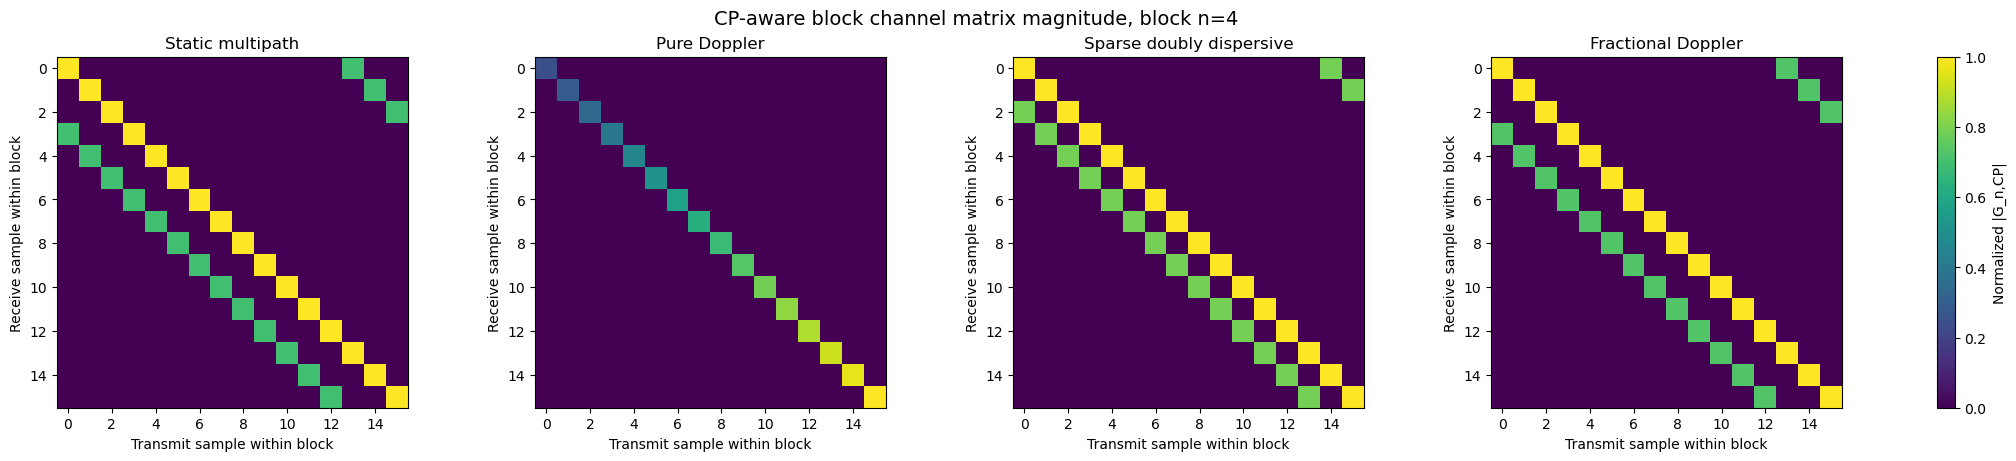

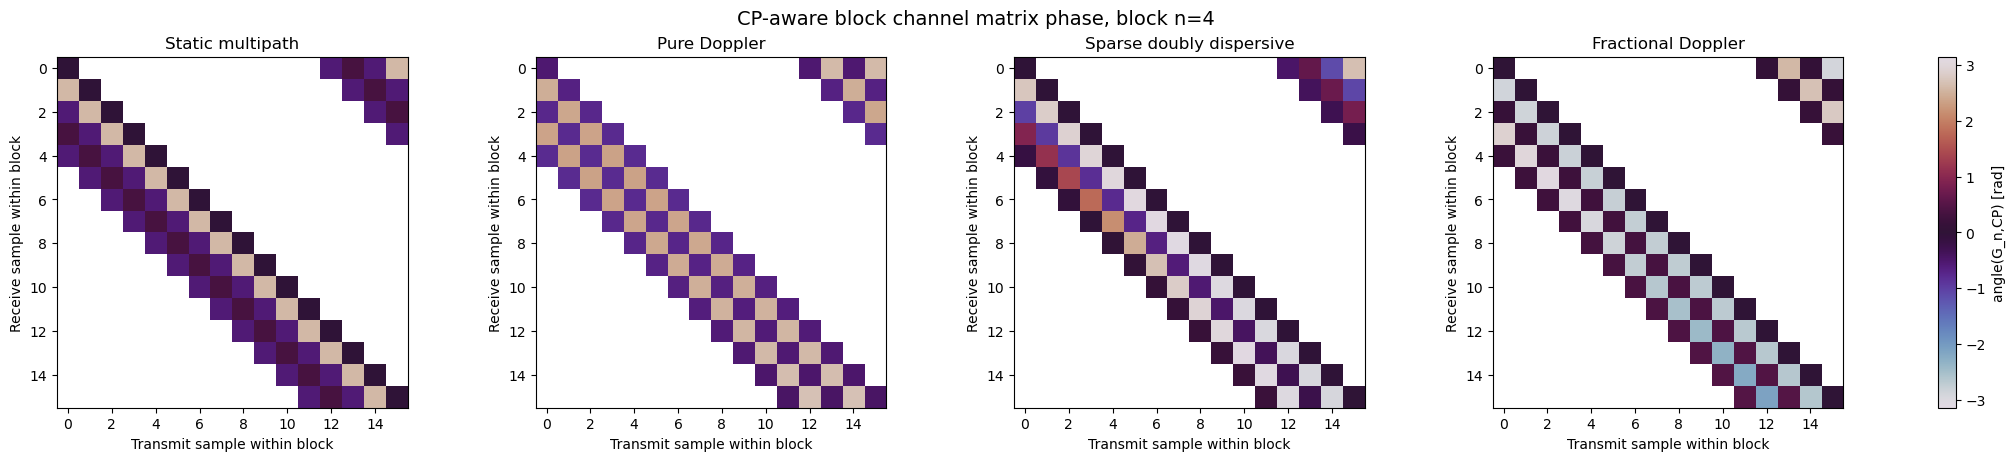

In [9]:
# Build the effective M x M channel seen by each OFDM symbol after CP removal.
# Map CP samples back onto the circular OFDM symbol support.
for name, data in channel_data.items():
    h_full = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]  # [time, delay]
    G_blocks_with_cp = np.zeros((N, M, M), dtype=np.complex128)

    for n in range(N):
        block_start = n * (M + CP_LEN)
        useful_start = block_start + CP_LEN

        for m_rx in range(M):
            q = useful_start + m_rx

            for ell in range(h_full.shape[1]):
                input_sample_with_cp = CP_LEN + m_rx - ell

                if 0 <= input_sample_with_cp < (M + CP_LEN):
                    if input_sample_with_cp < CP_LEN:
                        m_tx = M - CP_LEN + input_sample_with_cp
                    else:
                        m_tx = input_sample_with_cp - CP_LEN

                    if q < h_full.shape[0]:
                        G_blocks_with_cp[n, m_rx, m_tx] += h_full[q, ell]

    data["G_blocks_with_cp"] = G_blocks_with_cp
    data["G_block_with_cp"] = G_blocks_with_cp[block_to_show]

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G_block = data["G_block_with_cp"]
    G_abs = np.abs(G_block)
    G_abs = G_abs / (np.max(G_abs) + 1e-12)

    im = ax.imshow(G_abs, aspect="equal", origin="upper", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("Transmit sample within block")
    ax.set_ylabel("Receive sample within block")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |G_n,CP|")
fig.suptitle(f"CP-aware block channel matrix magnitude, block n={block_to_show}", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    G_block = data["G_block_with_cp"]
    G_phase = np.angle(G_block)
    G_phase = np.ma.array(G_phase, mask=(np.abs(G_block) < 1e-10))

    im = ax.imshow(G_phase, aspect="equal", origin="upper", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("Transmit sample within block")
    ax.set_ylabel("Receive sample within block")

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(G_n,CP) [rad]")
fig.suptitle(f"CP-aware block channel matrix phase, block n={block_to_show}", fontsize=14)
plt.show()


## 10. Circulant Structure and CP

The deviation from circulant structure is made explicit by computing the error matrix $E = G_n - \text{circ}(G_n[:,0])$, where $\text{circ}(\mathbf{c})$ denotes the circulant matrix generated by taking the first column of $G_n$ as its first column.

For the static multipath channel the error is numerically zero: the CP converts the linear convolution exactly into circular convolution, and $G_n$ is exactly circulant.

For the Doppler cases the error is non-zero. The time-variation of the channel within one block means that different rows of $G_n$ see slightly different channel realizations, so the entries along the same sub-diagonal are not constant. The magnitude of the error grows with the Doppler tap value and with the block length $M$: a faster-varying channel, or a longer block, produces larger deviations.

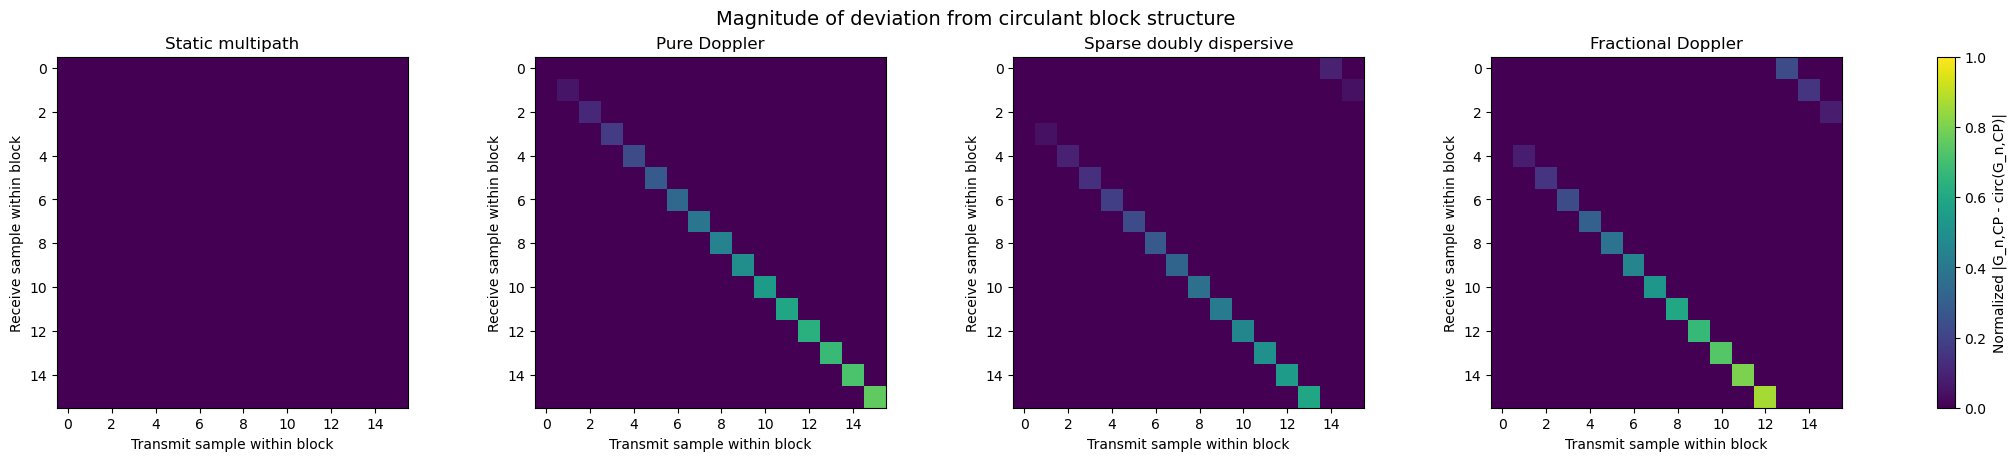

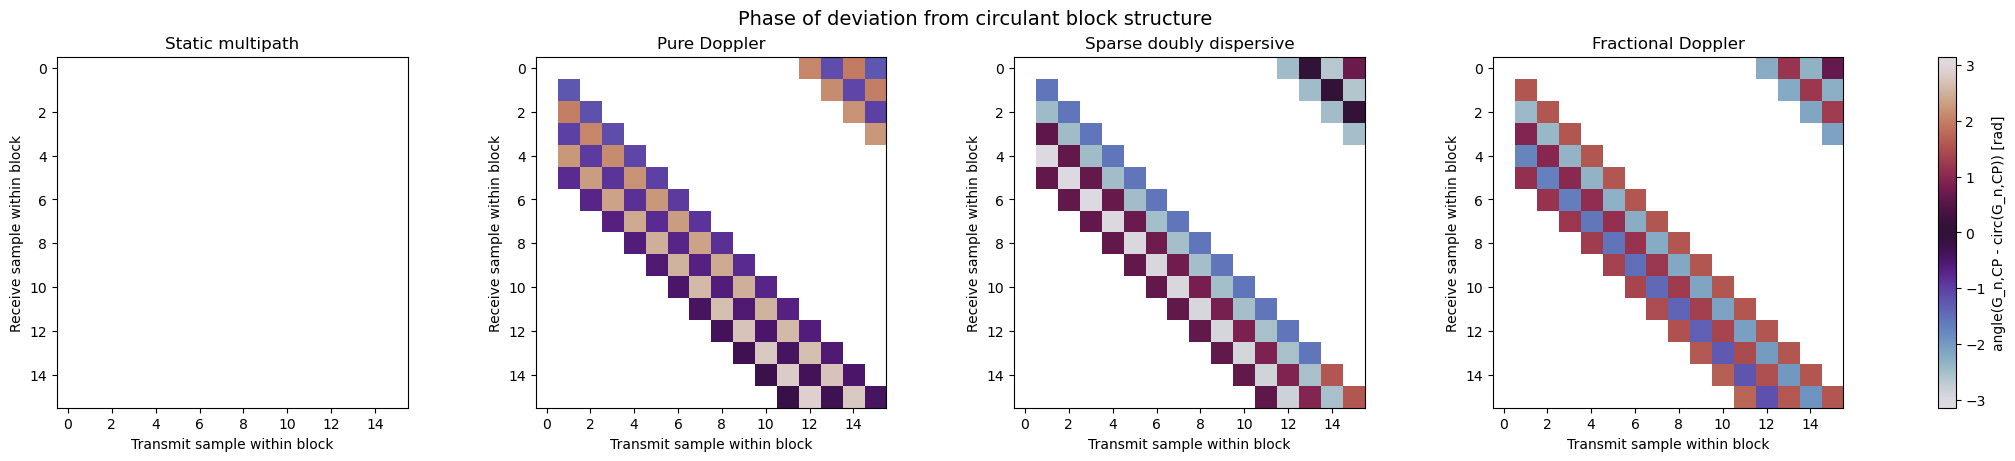

In [10]:
# Construct the circulant matrix generated by the first column.
# Measure how far the actual channel deviates from a circulant matrix.
for name, data in channel_data.items():
    G_block = data["G_block_with_cp"]
    first_col = G_block[:, 0]

    C = np.zeros_like(G_block)
    for row in range(M):
        for col in range(M):
            C[row, col] = first_col[(row - col) % M]

    data["G_block_circulant_approx"] = C
    data["G_block_circulant_error"] = G_block - C

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    E = data["G_block_circulant_error"]
    E_abs = np.abs(E)
    E_abs = E_abs / (np.max(np.abs(data["G_block_with_cp"])) + 1e-12)

    im = ax.imshow(E_abs, aspect="equal", origin="upper", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("Transmit sample within block")
    ax.set_ylabel("Receive sample within block")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |G_n,CP - circ(G_n,CP)|")
fig.suptitle("Magnitude of deviation from circulant block structure", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    E = data["G_block_circulant_error"]
    E_phase = np.angle(E)
    E_phase = np.ma.array(E_phase, mask=(np.abs(E) < 1e-10))

    im = ax.imshow(E_phase, aspect="equal", origin="upper", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("Transmit sample within block")
    ax.set_ylabel("Receive sample within block")

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(G_n,CP - circ(G_n,CP)) [rad]")
fig.suptitle("Phase of deviation from circulant block structure", fontsize=14)
plt.show()


## 11. DFT Effect and Intercarrier Interference

The DFT diagonalizes circulant matrices. Concretely, for a circulant block matrix $G_n$:

$$H_{f,n} = F \cdot G_n \cdot F^H$$

is diagonal, where $F$ is the normalized $M$-point DFT matrix. The diagonal entries give the complex channel gain at each subcarrier, and a single complex division per subcarrier recovers the transmitted symbol.

When $G_n$ deviates from circulant structure (Doppler), $H_{f,n}$ has non-zero off-diagonal entries. These off-diagonal entries are intercarrier interference (ICI): the signal transmitted on subcarrier $m'$ leaks into subcarrier $m$ at the receiver.

The ICI ratio is defined as the fraction of total received energy contained in the off-diagonal entries of $H_{f,n}$, averaged over all $N$ blocks:

$$\text{ICI ratio} = \frac{\sum_{m \neq m'} |H_{f,n}[m,m']|^2}{\sum_{m,m'} |H_{f,n}[m,m']|^2}$$

The bar chart shows this ratio for each channel case. Static multipath produces a ratio that is numerically zero. Pure Doppler produces the largest ratio; doubly dispersive and fractional Doppler fall between these extremes depending on the Doppler tap magnitudes used.

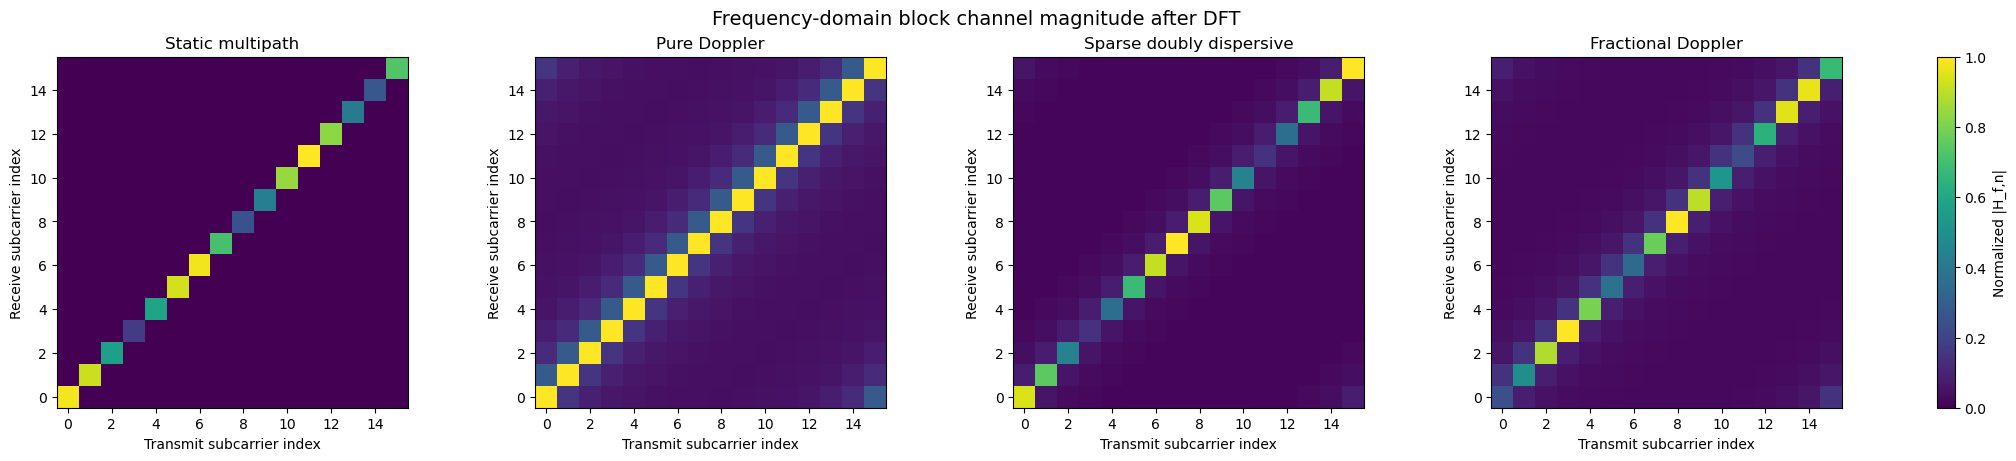

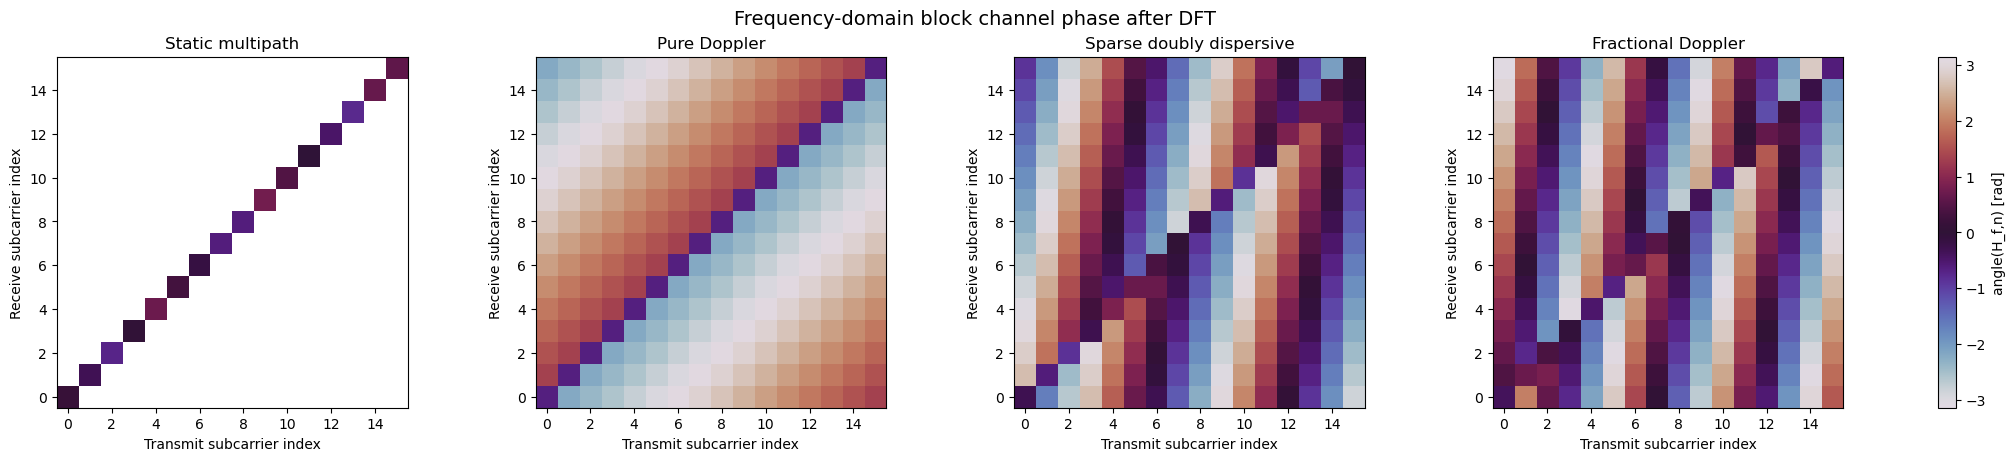

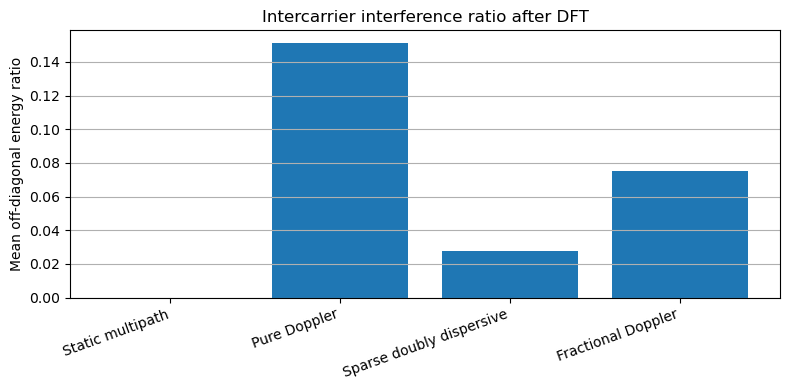

Static multipath             mean ICI ratio = 4.6929e-30
Pure Doppler                 mean ICI ratio = 1.5124e-01
Sparse doubly dispersive     mean ICI ratio = 2.7537e-02
Fractional Doppler           mean ICI ratio = 7.5251e-02


In [11]:
# Explicit M-point DFT matrix used for channel diagonalization.
# Transform the effective block channel into the frequency domain.
# Separate diagonal (desired) and off-diagonal (ICI) components.
# Measure the fraction of channel energy that leaks across subcarriers.
m = np.arange(M)
F = np.exp(-1j * 2 * np.pi * np.outer(m, m) / M) / np.sqrt(M)
Fh = F.conj().T

ici_rows = []

for name, data in channel_data.items():
    Hf_blocks = np.zeros_like(data["G_blocks_with_cp"])
    ici_ratios = []

    for n in range(N):
        Hf = F @ data["G_blocks_with_cp"][n] @ Fh
        Hf_blocks[n] = Hf

        diag = np.diag(np.diag(Hf))
        off = Hf - diag

        off_power = np.sum(np.abs(off) ** 2)
        total_power = np.sum(np.abs(Hf) ** 2) + 1e-12
        ici_ratios.append(off_power / total_power)

    data["Hf_blocks"] = Hf_blocks
    data["ici_ratios"] = np.array(ici_ratios)
    ici_rows.append((name, np.mean(ici_ratios)))

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    Hf = data["Hf_blocks"][block_to_show]
    H_abs = np.abs(Hf)
    H_abs = H_abs / (np.max(H_abs) + 1e-12)

    im = ax.imshow(H_abs, aspect="equal", origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("Transmit subcarrier index")
    ax.set_ylabel("Receive subcarrier index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |H_f,n|")
fig.suptitle("Frequency-domain block channel magnitude after DFT", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    Hf = data["Hf_blocks"][block_to_show]
    H_phase = np.angle(Hf)
    H_phase = np.ma.array(H_phase, mask=(np.abs(Hf) < 1e-10))

    im = ax.imshow(H_phase, aspect="equal", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("Transmit subcarrier index")
    ax.set_ylabel("Receive subcarrier index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(H_f,n) [rad]")
fig.suptitle("Frequency-domain block channel phase after DFT", fontsize=14)
plt.show()

plt.figure(figsize=(8, 4))
plt.bar([r[0] for r in ici_rows], [r[1] for r in ici_rows])
plt.ylabel("Mean off-diagonal energy ratio")
plt.title("Intercarrier interference ratio after DFT")
plt.xticks(rotation=20, ha="right")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

for name, value in ici_rows:
    print(f"{name:28s} mean ICI ratio = {value:.4e}")


## 12. Pass One OFDM Frame through Each Channel

The transmitted OFDM frame is propagated through each channel using the CP-aware block channel matrices. Complex AWGN is added directly to the useful received samples. An FFT per block then recovers the received time-frequency grid $Y_\text{tf}$.

For the static multipath channel the received grid shows a smoothly varying but time-invariant magnitude pattern -- frequency-selective fading with the same gain profile at every OFDM symbol. This is the condition under which single-tap equalization is effective.

For Doppler and doubly dispersive channels the magnitude pattern changes from symbol to symbol and the phase plot shows visible spreading. The distortion is caused by ICI contaminating each received subcarrier with contributions from its neighbours.

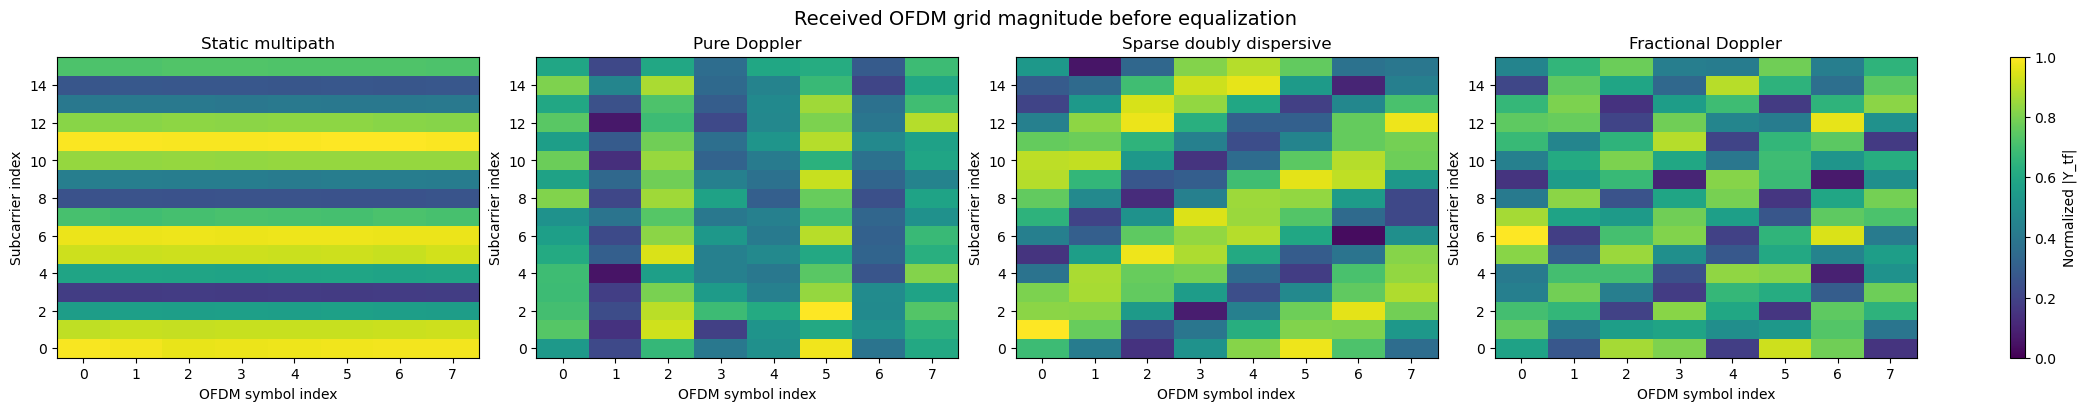

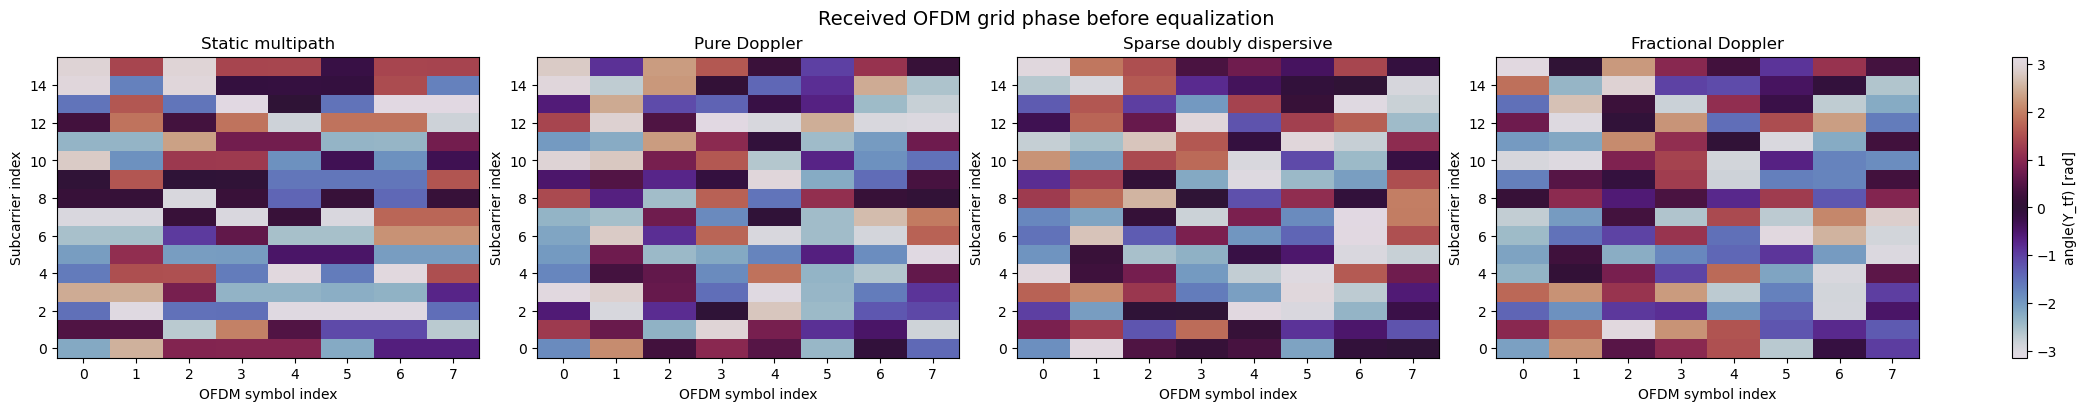

In [12]:
# Apply the effective CP-aware channel block by block.
# Add complex AWGN directly in the useful-symbol domain.
# Recover the received OFDM grid with an FFT.
noise_variance = 1e-4
rng = np.random.default_rng(10)

for name, data in channel_data.items():
    y_blocks_no_cp = np.zeros((N, M), dtype=np.complex128)

    for n in range(N):
        y_blocks_no_cp[n] = data["G_blocks_with_cp"][n] @ x_blocks_no_cp[n]

    noise = (
        rng.normal(size=y_blocks_no_cp.shape)
        + 1j * rng.normal(size=y_blocks_no_cp.shape)
    ) * np.sqrt(noise_variance / 2)

    y_blocks_no_cp_noisy = y_blocks_no_cp + noise
    Y_tf_rx = np.fft.fft(y_blocks_no_cp_noisy, n=M, axis=1) / np.sqrt(M)

    data["y_blocks_no_cp"] = y_blocks_no_cp
    data["Y_tf_rx"] = Y_tf_rx

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    Y_abs = np.abs(data["Y_tf_rx"]).T
    Y_abs = Y_abs / (np.max(Y_abs) + 1e-12)

    im = ax.imshow(Y_abs, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |Y_tf|")
fig.suptitle("Received OFDM grid magnitude before equalization", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    Y = data["Y_tf_rx"]
    Y_phase = np.angle(Y).T
    Y_phase = np.ma.array(Y_phase, mask=(np.abs(Y).T < 1e-10))

    im = ax.imshow(Y_phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(Y_tf) [rad]")
fig.suptitle("Received OFDM grid phase before equalization", fontsize=14)
plt.show()


## 13. Single-Tap Equalization and Constellation Comparison

The single-tap MMSE equalizer computes, for each subcarrier $m$ of each OFDM symbol $n$:

$$\hat{x}[n,m] = \frac{H^*_{f,n}[m,m] \cdot Y_\text{tf}[n,m]}{|H_{f,n}[m,m]|^2 + \sigma_w^2}$$

This is the best possible scalar correction given only the diagonal of $H_{f,n}$. Any off-diagonal ICI is treated as additional noise.

The constellation plots show transmitted symbols, the received grid before equalization, and the equalized estimates. The MSE values printed below the plots summarize the equalization quality for each channel case.

For static multipath, equalization is near-perfect and the MSE is close to the noise floor. For Doppler channels, the equalized constellation remains diffuse: the equalizer corrects the mean channel gain but cannot undo the ICI. The MSE floor after equalization is set by the ICI energy, not by the noise -- increasing SNR would not improve it.

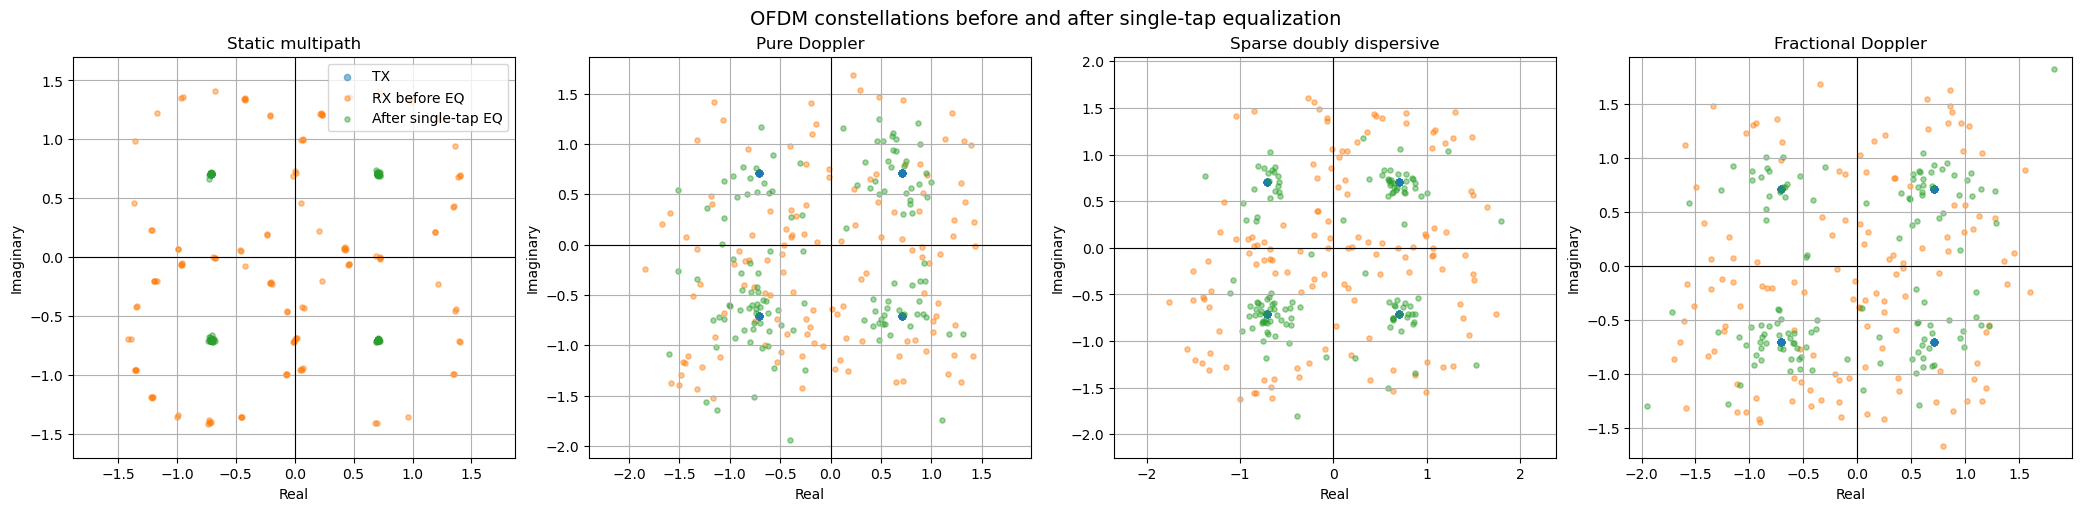

Static multipath             MSE before EQ = 4.8505e-01 | MSE after EQ = 1.7248e-04
Pure Doppler                 MSE before EQ = 5.1292e-01 | MSE after EQ = 2.0957e-01
Sparse doubly dispersive     MSE before EQ = 6.2526e-01 | MSE after EQ = 1.1180e-01
Fractional Doppler           MSE before EQ = 5.3133e-01 | MSE after EQ = 2.0044e-01


In [13]:
# Single-tap OFDM equalization assumes the channel is approximately diagonal.
# Per-subcarrier MMSE equalizer using only the diagonal channel terms.
for name, data in channel_data.items():
    X_hat = np.zeros_like(data["Y_tf_rx"])

    for n in range(N):
        Hf = data["Hf_blocks"][n]
        H_diag = np.diag(Hf)

        X_hat[n] = (
            np.conj(H_diag)
            * data["Y_tf_rx"][n]
            / (np.abs(H_diag) ** 2 + noise_variance)
        )

    data["X_hat_single_tap"] = X_hat

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 5), constrained_layout=True)

for ax, (name, data) in zip(axes, channel_data.items()):
    ax.scatter(np.real(X_tf.reshape(-1)), np.imag(X_tf.reshape(-1)), s=20, alpha=0.5, label="TX")
    ax.scatter(np.real(data["Y_tf_rx"].reshape(-1)), np.imag(data["Y_tf_rx"].reshape(-1)), s=14, alpha=0.45, label="RX before EQ")
    ax.scatter(np.real(data["X_hat_single_tap"].reshape(-1)), np.imag(data["X_hat_single_tap"].reshape(-1)), s=14, alpha=0.45, label="After single-tap EQ")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(True)
    ax.axis("equal")
    ax.set_title(name)
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")

axes[0].legend(loc="upper right")
fig.suptitle("OFDM constellations before and after single-tap equalization", fontsize=14)
plt.show()

for name, data in channel_data.items():
    mse_before = np.mean(np.abs(X_tf - data["Y_tf_rx"]) ** 2)
    mse_after = np.mean(np.abs(X_tf - data["X_hat_single_tap"]) ** 2)
    print(f"{name:28s} MSE before EQ = {mse_before:.4e} | MSE after EQ = {mse_after:.4e}")


## 14. Interpretation

Two conclusions follow from the matrix-level analysis in this notebook.

**CP creates circular convolution.** For a static multipath channel with delay spread no longer than the CP, the block channel matrix is exactly circulant. The DFT diagonalizes it, each subcarrier decouples from all others, and single-tap equalization is exact regardless of how frequency-selective the channel is.

**Doppler breaks circulant structure.** Time variation within one OFDM symbol period causes entries along the same sub-diagonal of the block matrix to differ. After the DFT, these variations appear as off-diagonal energy -- ICI. Single-tap equalization cannot remove ICI because it operates only on the diagonal. The resulting error floor grows with Doppler spread and is independent of SNR.

This motivates the OTFS approach taken in Notebooks 3 and 4. Instead of placing information on individual time-frequency resources where Doppler causes leakage between neighbours, OTFS places information in the delay-Doppler domain. The delay-Doppler channel representation has at most $P$ non-zero entries for a $P$-path channel, and the OTFS input-output relation remains structured even under strong Doppler -- the subject of the next notebook.